### All imports

In [2]:
from time import strftime, time
from typing import Literal

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

try:
    import torch
except ImportError:
    torch = None
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from src.backend import BackendPolicy, backend
from src.layers import ELU, BatchNormalization, Conv1D, Dense, Dropout, GlobalConcatPool1D, LeakyReLU, Softmax
from src.loss.cross_entropy import CrossEntropy
from src.models import Network, Sequential
from src.models.history import TrainingHistory
from src.optimizer import Adam

### Util function for loading and preparing the dataset
The `prepare_har_dataset` function converts raw CSV data into structured, model-ready tensors. It handles the "heavy lifting" such as:
- Reshaping the flat vectors into 3D shape (Samples, Channels, Time Steps)
- Providing Accelerometer and Gyroscope rotation-invariant features as additional channels
- Normalizing the data

The `remap_dataset` is a utility function that allows to filter or re-index the labels for specific experiments (e.g. combining sit and sit-talk into one "sit" class).

In [3]:
def prepare_har_dataset(
    csv_path: str, mode: Literal["raw", "mag", "hybrid"] = "hybrid", shuffle: bool = True, random_state: int | None = None
) -> tuple[np.ndarray, np.ndarray, np.ndarray, StandardScaler]:
    """
    Loads the HAR dataset from a CSV file and prepares it for training.
    Args:
        csv_path: Path to the CSV file containing the dataset.
        mode: Determines the type of features to prepare. Options are:
            - 'raw': Use only the raw accelerometer and gyroscope data (6 channels).
            - 'mag': Use only the magnitude of accelerometer and gyroscope data (2 channels).
            - 'hybrid': Use both raw and magnitude features (8 channels).
    """
    raw_data = np.genfromtxt(csv_path, delimiter=",")
    Y = raw_data[:, 9000].astype("int32")
    features_raw = raw_data[:, :9000].astype("float32")
    lengths = raw_data[:, 9001].astype("float32")
    num_samples = features_raw.shape[0]
    time_steps = 1500

    X_6 = np.zeros((num_samples, time_steps, 6), dtype="float32")
    for i in range(6):
        X_6[:, :, i] = features_raw[:, i * time_steps : (i + 1) * time_steps]

    acc_mag = np.linalg.norm(X_6[:, :, 0:3], axis=2, keepdims=True)
    gyro_mag = np.linalg.norm(X_6[:, :, 3:6], axis=2, keepdims=True)

    if mode == "raw":
        X_data = X_6
    elif mode == "mag":
        X_data = np.concatenate([acc_mag, gyro_mag], axis=2)
    else:
        X_data = np.concatenate([X_6, acc_mag, gyro_mag], axis=2)

    num_ch = X_data.shape[2]
    scaler = StandardScaler()
    X_flat = X_data.reshape(-1, num_ch)
    X_scaled_flat = scaler.fit_transform(X_flat)
    X_final = X_scaled_flat.reshape(num_samples, time_steps, num_ch)
    mask = np.arange(time_steps) < lengths[:, None]
    X_final[~mask] = 0.0
    X_final = np.transpose(X_final, (0, 2, 1))
    if shuffle:
        indices = np.arange(num_samples)
        rng = np.random.default_rng(seed=random_state)
        rng.shuffle(indices)
        X_final = X_final[indices]
        Y = Y[indices]
        lengths = lengths[indices]

    return X_final, Y, lengths, scaler


def remap_dataset(
    X: np.ndarray, Y: np.ndarray, lengths: np.ndarray, config: dict[int, str]
) -> tuple[np.ndarray, np.ndarray, np.ndarray, list[str]]:
    """
    Remaps the dataset labels according to the provided configuration.
    Args:
        X: Input features.
        Y: Original labels.
        lengths: Lengths of each sequence.
        config: Mapping of old labels to new labels.
    Returns:
        Remapped features, labels, lengths, and unique labels.
    """
    new_X, new_Y, new_lengths = [], [], []
    unique_labels = sorted(set(config.values()))
    label_to_id = {name: i for i, name in enumerate(unique_labels)}
    for i in range(len(Y)):
        old_id = int(Y[i])
        if old_id in config:
            new_X.append(X[i])
            new_lengths.append(lengths[i])
            new_Y.append(label_to_id[config[old_id]])
    return np.array(new_X), np.array(new_Y), np.array(new_lengths), unique_labels


def prepare_model(labels: list, scaler: StandardScaler, lr: float = 1e-3) -> Network:
    optimizer = Adam(learning_rate=lr)
    loss_fn = CrossEntropy()
    model = Sequential(
        [
            Conv1D(filters=32, kernel_size=31, stride=1, padding=15, name="conv1"),
            BatchNormalization(name="bn1"),
            LeakyReLU(name="leaky_relu1"),
            Conv1D(filters=64, kernel_size=15, stride=2, padding=7, name="conv2"),
            BatchNormalization(name="bn2"),
            LeakyReLU(name="leaky_relu2"),
            Dropout(0.2, name="dropout1"),
            Conv1D(filters=128, kernel_size=7, stride=2, padding=3, name="conv3"),
            BatchNormalization(name="bn3"),
            ELU(name="elu1"),
            GlobalConcatPool1D(name="masked_gap"),
            Dense(128, name="dense1"),
            BatchNormalization(name="bn4"),
            ELU(name="elu2"),
            Dropout(0.5, name="dropout2"),
            Dense(len(labels), name="dense2"),
            Softmax(name="softmax"),
        ]
    )
    model.compile(optimizer=optimizer, loss=loss_fn)
    model.activity_labels = labels
    model.scaler = scaler
    return model


def to_one_hot(Y, num_classes):
    return np.eye(num_classes)[Y.astype(int)]

In [4]:
def plot_training_history(history):
    sns.set_style("whitegrid")
    train_losses = history.metrics["train_loss"]
    epochs = range(1, len(train_losses) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    ax1.plot(epochs, train_losses, label="Train Loss", marker="o", markersize=4, alpha=0.7)
    has_val = "val_loss" in history.metrics and len(history.metrics["val_loss"]) > 0
    if has_val:
        val_losses = history.metrics["val_loss"]
        ax1.plot(epochs, val_losses, label="Val Loss", marker="s", markersize=4, color="orange")
        if history.best_epoch is not None:
            best_x = history.best_epoch + 1
            best_y = val_losses[history.best_epoch]
            ax1.axvline(x=best_x, color="red", linestyle="--", alpha=0.6, label="Best Epoch")
            ax1.scatter(best_x, best_y, color="red", marker="*", s=100, zorder=5)

    title = f"Training"
    if has_val:
        title += " and Validation"
    title += " Loss"

    ax1.set_title(title, fontweight="bold")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.legend()

    if "train_acc" in history.metrics:
        ax2.plot(epochs, history.metrics["train_acc"], label="Train Acc", marker="o", markersize=4, alpha=0.7)

    if "val_acc" in history.metrics and len(history.metrics["val_acc"]) > 0:
        val_accs = history.metrics["val_acc"]
        ax2.plot(epochs, val_accs, label="Val Acc", marker="s", markersize=4, color="green")
        if history.best_epoch is not None:
            best_x = history.best_epoch + 1
            ax2.axvline(x=best_x, color="red", linestyle="--", alpha=0.6, label="Best Epoch")

    title = f"Training"
    if has_val:
        title += " and Validation"
    title += " Accuracy"
    ax2.set_title(title, fontweight="bold")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Accuracy")
    ax2.legend()

    plt.tight_layout()
    plt.show()


def plot_confusion_matrix(y_true, y_pred, model, lengths_test, activity_map):
    cm = confusion_matrix(y_true, y_pred)
    num_classes = len(activity_map)
    plt.figure(figsize=(12, 10))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=[activity_map[i] for i in range(num_classes)],
        yticklabels=[activity_map[i] for i in range(num_classes)],
    )
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title("Confusion Matrix")
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.show()


def get_detailed_metrics(y_test, y_pred_probs, activity_map):
    y_true = np.argmax(y_test, axis=1)
    y_pred = np.argmax(y_pred_probs, axis=1)

    report = classification_report(
        y_true,
        y_pred,
        target_names=[activity_map[i] for i in range(len(activity_map))],
        output_dict=True,
        zero_division=0,
    )
    global_metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": report["macro avg"]["f1-score"],
        "Macro Precision": report["macro avg"]["precision"],
        "Macro Recall": report["macro avg"]["recall"],
    }

    df_classes = pd.DataFrame(report).transpose()
    df_classes = df_classes.drop(["macro avg", "weighted avg"], errors="ignore")

    return global_metrics, df_classes


def plot_class_performance(df_classes, metric: Literal["precision", "recall", "f1-score", "support"] = "f1-score"):
    valid_metrics = df_classes.columns.tolist()
    if metric not in valid_metrics:
        raise ValueError(f"Invalid metric '{metric}'. Choose from {valid_metrics}")

    plt.figure(figsize=(12, 8))
    df_sorted = df_classes.sort_values(by=metric, ascending=True)
    colors = sns.color_palette("RdYlGn", len(df_sorted))
    ax = sns.barplot(x=df_sorted[metric], y=df_sorted.index, palette=colors, hue=df_sorted.index, legend=False)
    mean_val = df_sorted[metric].mean()
    plt.axvline(x=mean_val, color="blue", linestyle="--", label=f"Mean {metric.capitalize()} ({mean_val:.2f})")
    plt.title(f"{metric.capitalize()} per Activity", fontsize=15, fontweight="bold")
    plt.xlabel(metric.capitalize())
    plt.ylabel("Activity")
    if metric != "support":
        plt.xlim(0, 1.05)

    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()


def plot_most_confused_classes(df_classes, top_n=5):
    df_classes["error_rate"] = 1 - df_classes["recall"]
    df_err = df_classes.sort_values(by="error_rate", ascending=False).head(top_n)

    plt.figure(figsize=(10, 6))
    sns.set_style("whitegrid")

    ax = sns.barplot(x=df_err["error_rate"], y=df_err.index, palette="Reds_r", hue=df_err.index, legend=False)

    ax.bar_label(ax.containers[0], fmt=lambda x: f"{x * 100:.1f}%", padding=8, fontweight="bold", fontsize=11)

    plt.title(f"Top {top_n} Most Confused Activities (By Total Misses)", fontsize=15, fontweight="bold")
    plt.xlabel("Error Rate (1 - Recall)")
    plt.ylabel("Activity")
    plt.xlim(0, 1.1)

    plt.tight_layout()
    plt.show()


def plot_top_mutual_confusions(y_test, y_pred_probs, activity_map, top_n=10):
    y_true = np.argmax(y_test, axis=1)
    y_pred = np.argmax(y_pred_probs, axis=1)

    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]

    mutual_confusions = []
    num_classes = len(activity_map)
    for i in range(num_classes):
        for j in range(i + 1, num_classes):
            combined_error = cm_norm[i, j] + cm_norm[j, i]

            mutual_confusions.append(
                {"Class_A": activity_map[i], "Class_B": activity_map[j], "Mutual_Error": combined_error}
            )

    mutual_df = pd.DataFrame(mutual_confusions).sort_values(by="Mutual_Error", ascending=False).head(top_n)
    mutual_df["Pair"] = mutual_df["Class_A"] + " ↔ " + mutual_df["Class_B"]
    plt.figure(figsize=(12, 7))
    sns.set_style("whitegrid")
    ax = sns.barplot(x="Mutual_Error", y="Pair", data=mutual_df, palette="viridis", hue="Pair", legend=False)
    ax.bar_label(ax.containers[0], fmt="%.2f", padding=8, fontweight="bold")
    plt.title(f"Top {top_n} Fundamentally Entangled Activities", fontsize=15, fontweight="bold")
    plt.xlabel("Total Mutual Confusion (Sum of Bidirectional Normalized Error)")
    plt.xlim(0, max(mutual_df["Mutual_Error"]) * 1.2)
    plt.tight_layout()
    plt.show()

In [5]:
dataset_path = r"data\KU-HAR_v1.0_raw_samples.csv"
activity_map = {
    0: "Stand",
    1: "Sit",
    2: "Talk-sit",
    3: "Talk-stand",
    4: "Stand-sit",
    5: "Lay",
    6: "Lay-stand",
    7: "Pick",
    8: "Jump",
    9: "Push-up",
    10: "Sit-up",
    11: "Walk",
    12: "Walk-backward",
    13: "Walk-circle",
    14: "Run",
    15: "Stair-up",
    16: "Stair-down",
    17: "Table-tennis",
}
num_classes = len(activity_map)
backend.configure(policy=BackendPolicy(use_gpu=True), dataset_bytes=1024 * 1024 * 1024 * 1024)

2026-11-12 08:09:29,506 | INFO | src.backend | GPU requested. Dataset size: 1099511627776 bytes. Minimum for GPU: 8000000 bytes.
2026-11-12 08:09:29,507 | INFO | src.backend | CuPy available: False.
2026-11-12 08:09:29,507 | INFO | src.backend | Using backend: numpy


# 1. Neural network evaluation (raw)

In [6]:
X_RAW, Y_RAW, LENGHTS_RAW, SCALER_RAW = prepare_har_dataset(
    dataset_path, mode="raw", shuffle=False, random_state=42
)

_X_tmp, X_raw_test, _Y_tmp, Y_raw_test_int, _len_tmp, lengths_raw_test = train_test_split(
    X_RAW, Y_RAW, LENGHTS_RAW, test_size=0.2, random_state=42, stratify=Y_RAW
)
X_raw_train, X_raw_val, Y_raw_train_int, Y_raw_val_int, lengths_raw_train, lengths_raw_val = train_test_split(
    _X_tmp, _Y_tmp, _len_tmp, test_size=0.25, random_state=42, stratify=_Y_tmp
)
del _X_tmp, _Y_tmp, _len_tmp

Y_raw_train = to_one_hot(Y_raw_train_int, num_classes)
Y_raw_val   = to_one_hot(Y_raw_val_int,   num_classes)
Y_raw_test  = to_one_hot(Y_raw_test_int,  num_classes)

labels_raw = [activity_map[i] for i in range(num_classes)]

X_raw_train_T = np.transpose(X_raw_train, (0, 2, 1))
X_raw_val_T   = np.transpose(X_raw_val,   (0, 2, 1))
X_raw_test_T  = np.transpose(X_raw_test,  (0, 2, 1))

print(f"RAW dataset: {X_RAW.shape[0]} samples | {X_RAW.shape[1]} channels | {X_RAW.shape[2]} timesteps")
print(f"Split  →  Train: {X_raw_train.shape[0]}  Val: {X_raw_val.shape[0]}  Test: {X_raw_test.shape[0]}")
print(f"Class balance (train): {np.bincount(Y_raw_train_int)}")
print(f"Class balance (val):   {np.bincount(Y_raw_val_int)}")
print(f"Class balance (test):  {np.bincount(Y_raw_test_int)}")

RAW dataset: 9185 samples | 6 channels | 1500 timesteps
Split  →  Train: 5511  Val: 1837  Test: 1837
Class balance (train): [358 358 347 356 475 353 325 380 332 308 248 347 130 104 303 305 319 163]
Class balance (val):   [119 119 116 119 158 117 109 127 110 102  83 116  44  34 101 101 107  55]
Class balance (test):  [119 119 116 119 158 118 109 127 111 102  83 116  44  34 101 101 106  54]


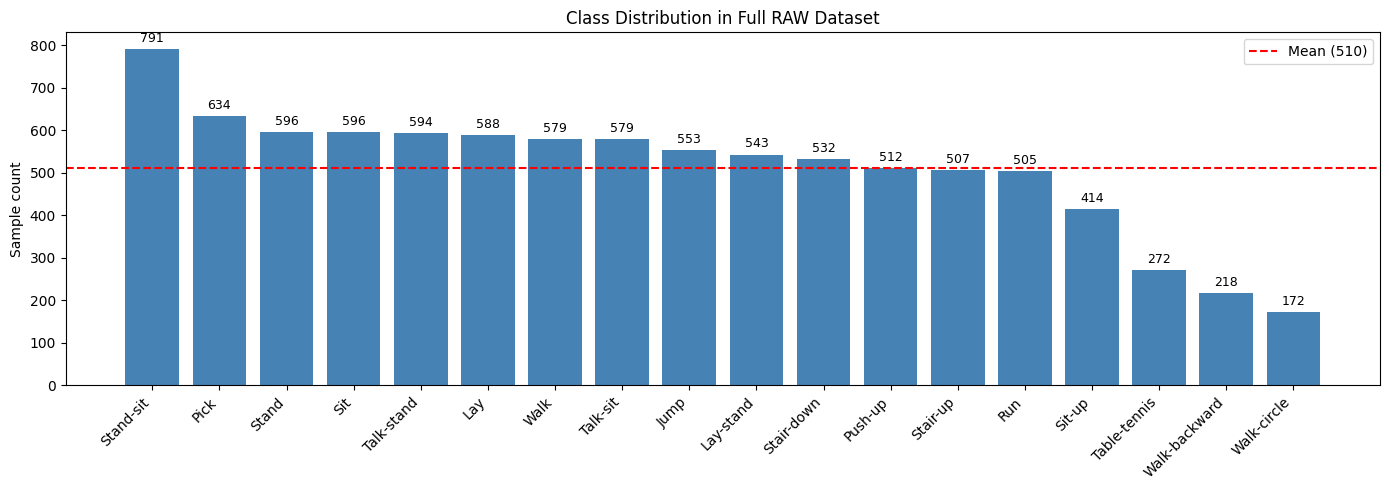

Most frequent:  Stand-sit — 791 samples
Least frequent: Walk-circle — 172 samples
Imbalance ratio: 4.6x


In [7]:
import matplotlib.pyplot as plt
import numpy as np

counts = np.bincount(Y_RAW)
order = np.argsort(counts)[::-1]

plt.figure(figsize=(14, 5))
bars = plt.bar(range(num_classes), counts[order], color='steelblue')
plt.xticks(range(num_classes), [labels_raw[i] for i in order], rotation=45, ha='right')
plt.axhline(counts.mean(), color='red', linestyle='--', label=f'Mean ({counts.mean():.0f})')
plt.bar_label(bars, padding=3, fontsize=9)
plt.title('Class Distribution in Full RAW Dataset')
plt.ylabel('Sample count')
plt.legend()
plt.tight_layout()
plt.show()

print(f"Most frequent:  {labels_raw[counts.argmax()]} — {counts.max()} samples")
print(f"Least frequent: {labels_raw[counts.argmin()]} — {counts.min()} samples")
print(f"Imbalance ratio: {counts.max() / counts.min():.1f}x")

In [ ]:
model = prepare_model(labels=labels_raw, scaler=SCALER_RAW)

history, total_time = model.fit(
    x_train=X_raw_train,
    y_train=Y_raw_train,
    x_val=X_raw_val,
    y_val=Y_raw_val,
    epochs=150,
    batch_size=256,
    verbose=2,
    mask=lengths_raw_train,
    val_mask=lengths_raw_val,
    lr_decay_epochs=30,
    lr_decay=0.75,
    early_stopping_patience=20,
    early_stopping_min_delta=1e-3,
)

model.save(r"models\har_model_raw_v0.nnp")

Epoch 1/2, 50.78s/epoch - ETA: 00:00:50
Loss: 2.518443, Acc: 0.2633
Val Loss: 1.657338 - Val Acc: 0.4807
Epoch 2/2, 50.44s/epoch - ETA: 00:00:00
Loss: 1.599872, Acc: 0.4682
Val Loss: 1.298838 - Val Acc: 0.6081

Training Complete. Total Time: 00:01:41


In [12]:
print(f"Total training time: {total_time:.2f} seconds")
for metric_name, values in history.metrics.items():
    print(f"{metric_name}: {values}")

Total training time: 101.43 seconds
train_loss: [2.5184426307678223, 1.5998717546463013]
val_loss: [1.6573379039764404, 1.298838496208191]
train_acc: [0.2632915986209399, 0.46815459989112684]
val_acc: [0.48067501360914533, 0.608056614044638]
lr: [0.001, 0.001]
epoch_time: [50.784438610076904, 50.43518328666687]


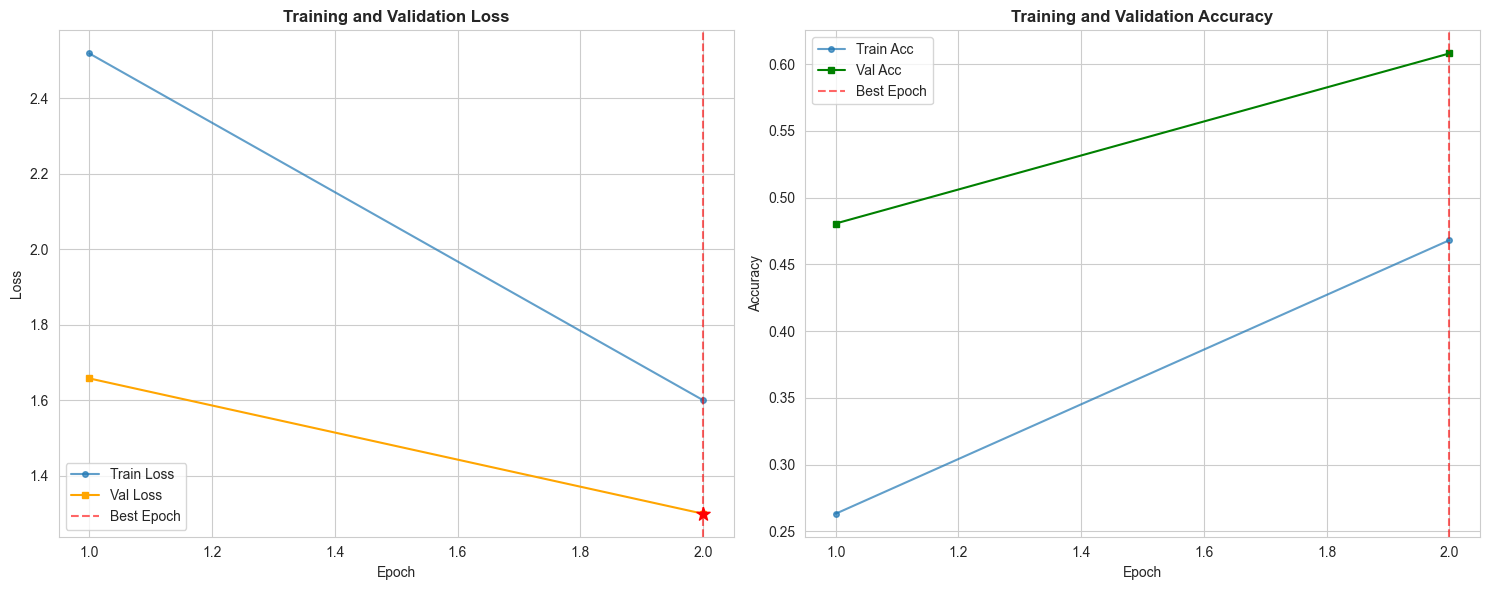

In [11]:
plot_training_history(history)

## 1.1 Evaluation

### 1.1.1 Confisuion matrix

In [ ]:
model: Sequential = Network.load(r"models\har_model_raw_v0.nnp")

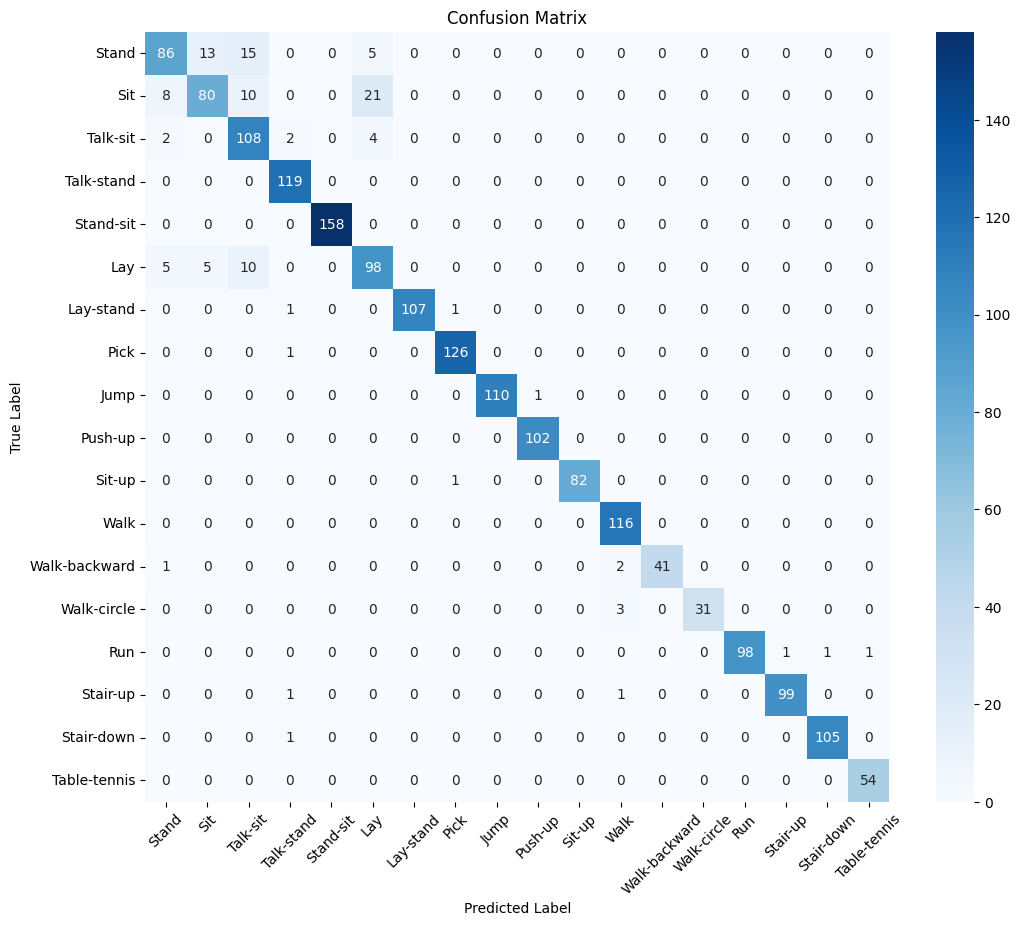

In [ ]:
_preds_raw = model.predict(X_raw_test, mask=lengths_raw_test)
y_raw_true_idx = np.argmax(Y_raw_test, axis=1)
y_raw_pred_idx = np.argmax(_preds_raw, axis=1)
plot_confusion_matrix(y_raw_true_idx, y_raw_pred_idx, model, lengths_test=lengths_raw_test, activity_map=model.activity_labels)

### 1.1.2 Metrics per activity

In [ ]:
predictions = model.predict(X_raw_test, mask=lengths_raw_test)
global_m, class_df = get_detailed_metrics(Y_raw_test, predictions, activity_map)

In [ ]:
print(class_df)

               precision    recall  f1-score     support
Stand           0.843137  0.722689  0.778281  119.000000
Sit             0.816327  0.672269  0.737327  119.000000
Talk-sit        0.755245  0.931034  0.833977  116.000000
Talk-stand      0.952000  1.000000  0.975410  119.000000
Stand-sit       1.000000  1.000000  1.000000  158.000000
Lay             0.765625  0.830508  0.796748  118.000000
Lay-stand       1.000000  0.981651  0.990741  109.000000
Pick            0.984375  0.992126  0.988235  127.000000
Jump            1.000000  0.990991  0.995475  111.000000
Push-up         0.990291  1.000000  0.995122  102.000000
Sit-up          1.000000  0.987952  0.993939   83.000000
Walk            0.950820  1.000000  0.974790  116.000000
Walk-backward   1.000000  0.931818  0.964706   44.000000
Walk-circle     1.000000  0.911765  0.953846   34.000000
Run             1.000000  0.970297  0.984925  101.000000
Stair-up        0.990000  0.980198  0.985075  101.000000
Stair-down      0.990566  0.990

### 1.1.2.1 F1-score

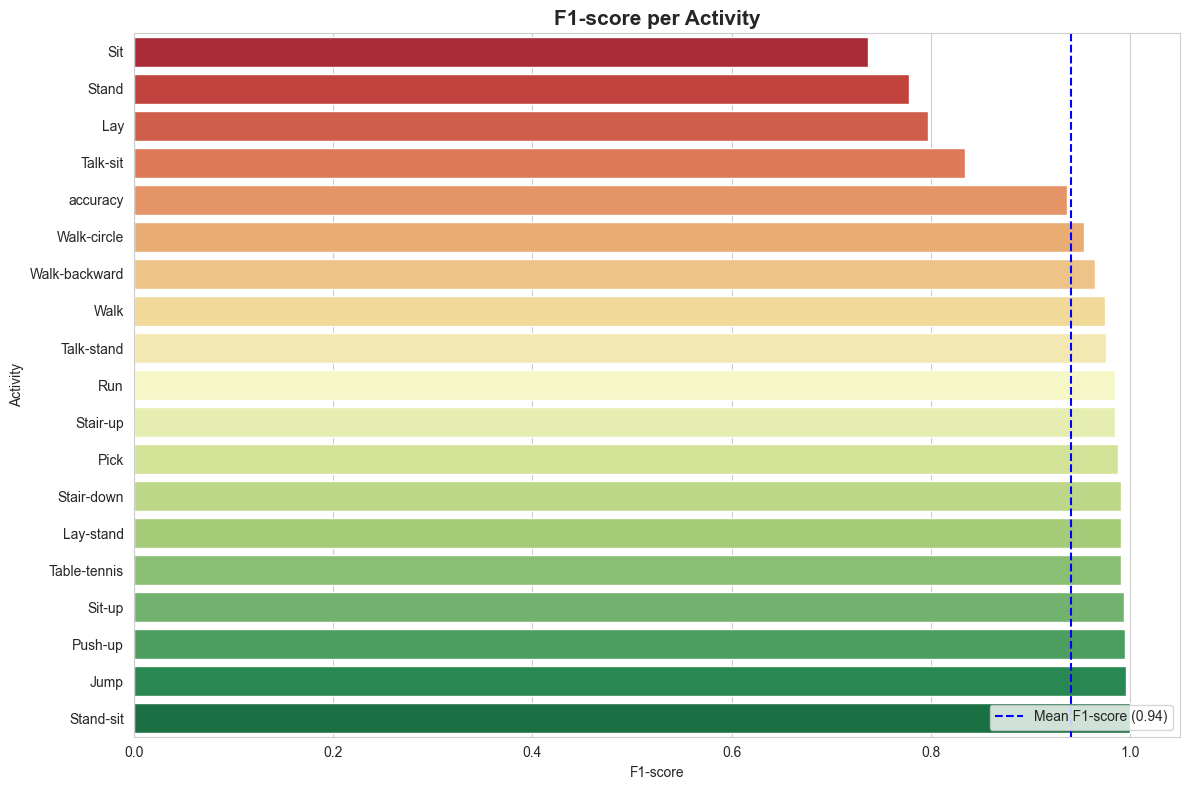

In [ ]:
plot_class_performance(class_df, metric="f1-score")

### 1.1.2.2 Recall

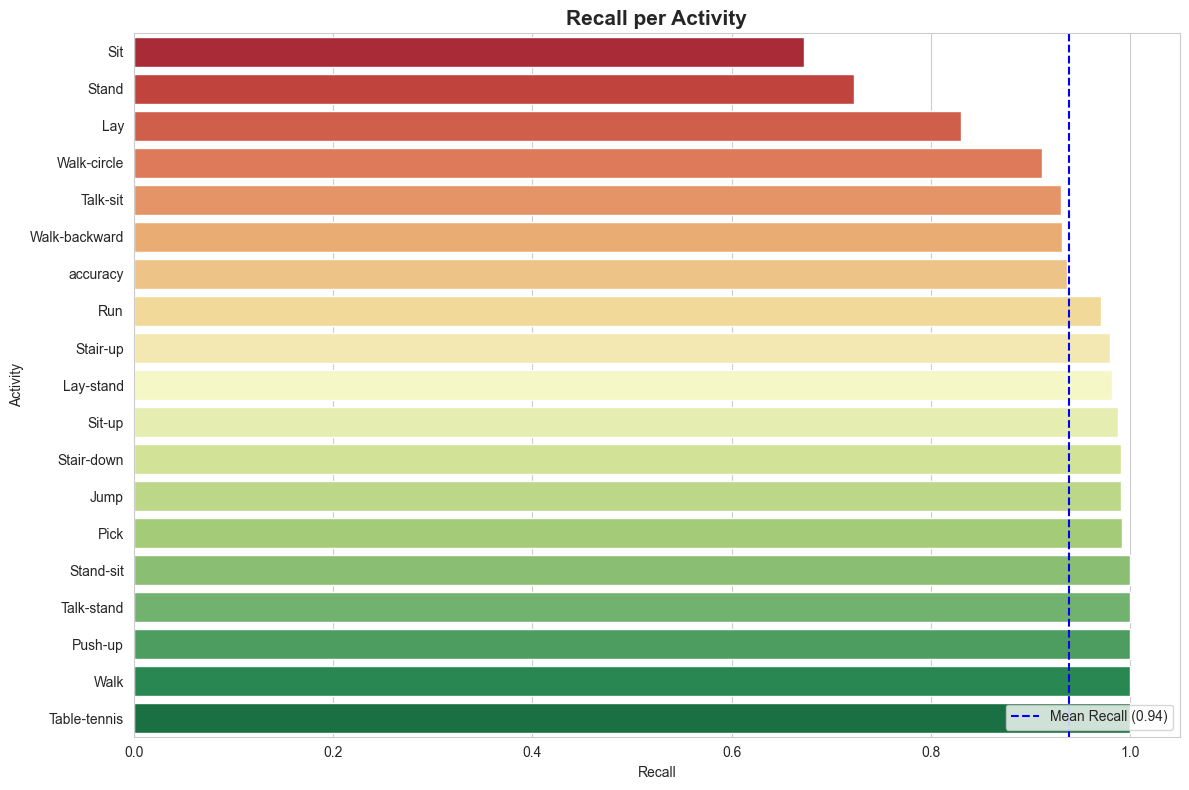

In [ ]:
plot_class_performance(class_df, metric="recall")

### 1.1.2.3 Precision

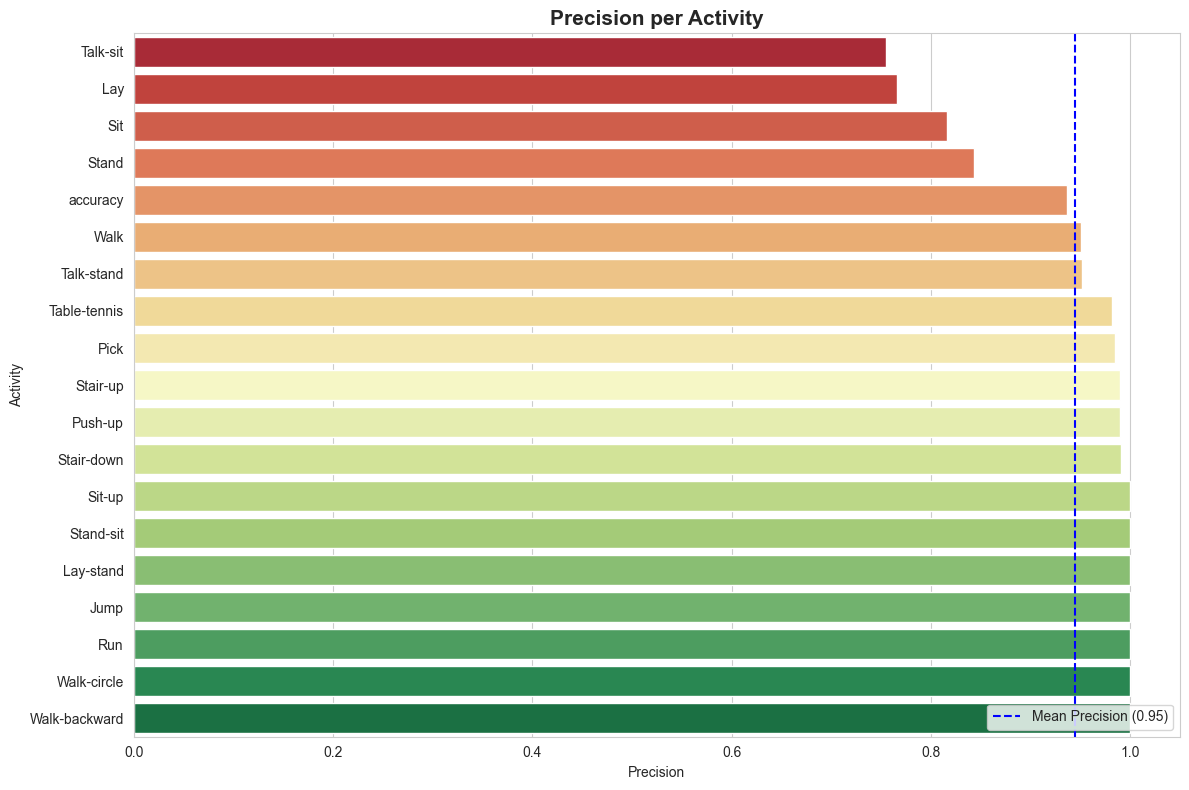

In [ ]:
plot_class_performance(class_df, metric="precision")

### 1.1.2.4 Top confused classes by total misses

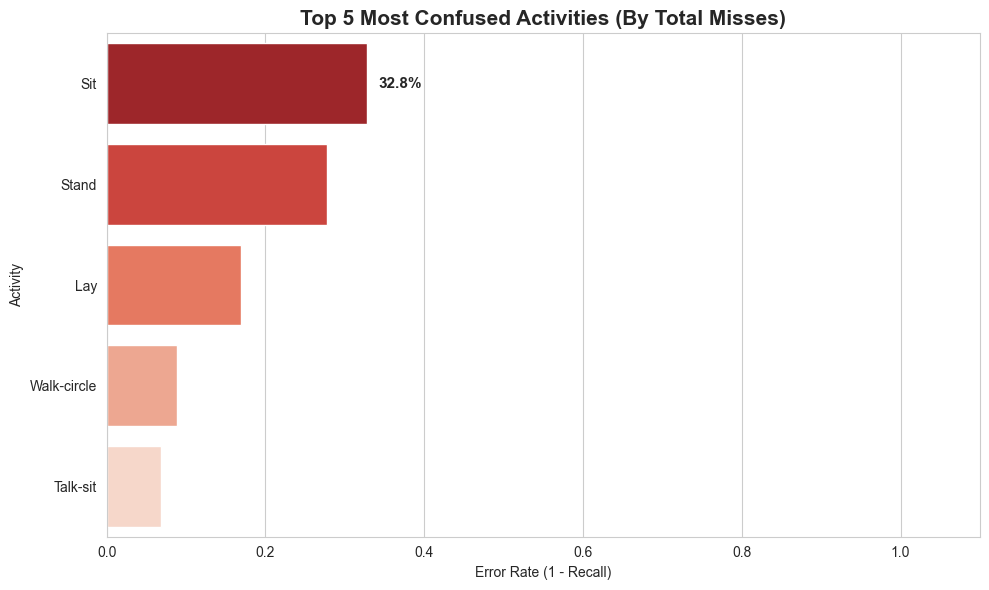

In [ ]:
plot_most_confused_classes(class_df, top_n=5)

### 1.1.2.5 Top mutually confused classes

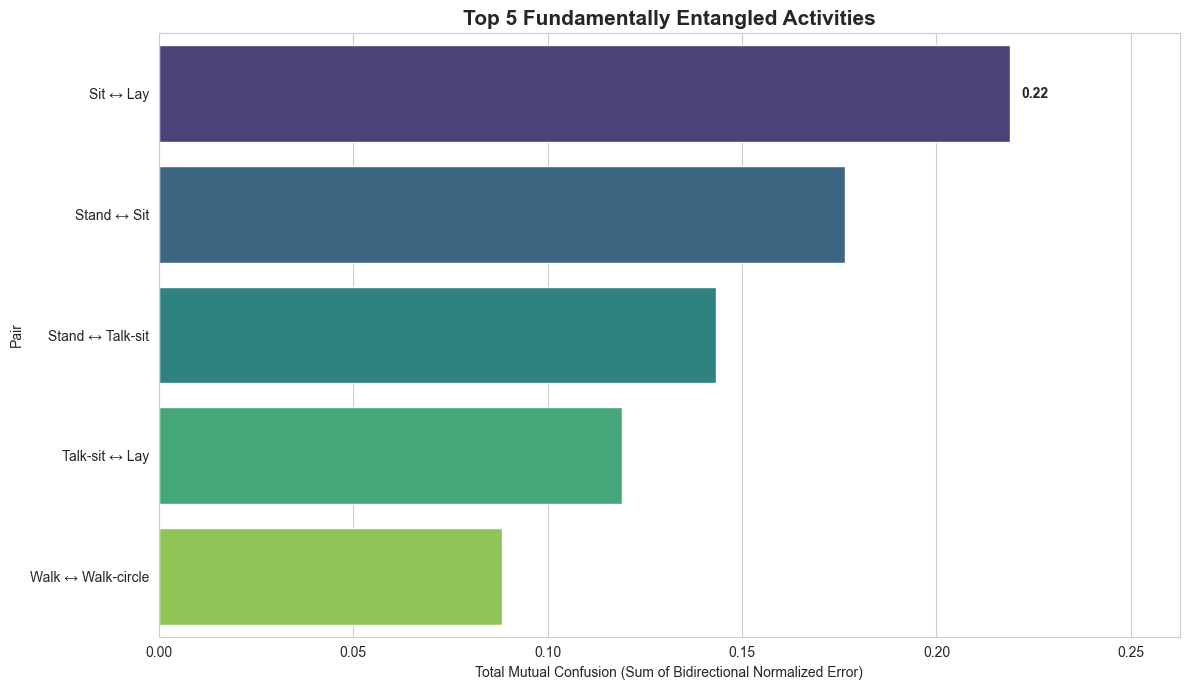

In [ ]:
plot_top_mutual_confusions(Y_raw_test, predictions, activity_map, top_n=5)

# 2. Neural network evaluation with the original 18 classes (magnitude)

In [ ]:
X_MAGNITUDE, Y_MAGNITUDE, LENGHTS_MAGNITUDE, SCALER_MAGNITUDE = prepare_har_dataset(
    dataset_path, mode="mag", shuffle=False, random_state=42
)

In [ ]:
_X_tmp, X_magnitude_test, _Y_tmp, Y_magnitude_test_int, _len_tmp, lengths_magnitude_test = train_test_split(
    X_MAGNITUDE, Y_MAGNITUDE, LENGHTS_MAGNITUDE, test_size=0.2, random_state=42, stratify=Y_MAGNITUDE
)
X_magnitude_train, X_magnitude_val, Y_magnitude_train_int, Y_magnitude_val_int, lengths_magnitude_train, lengths_magnitude_val = train_test_split(
    _X_tmp, _Y_tmp, _len_tmp, test_size=0.25, random_state=42, stratify=_Y_tmp
)
del _X_tmp, _Y_tmp, _len_tmp

labels_magnitude = [activity_map[i] for i in range(num_classes)]
Y_magnitude_train = np.eye(num_classes)[Y_magnitude_train_int.astype(int)]
Y_magnitude_val   = np.eye(num_classes)[Y_magnitude_val_int.astype(int)]
Y_magnitude_test  = np.eye(num_classes)[Y_magnitude_test_int.astype(int)]

print(f"Magnitude split  →  Train: {X_magnitude_train.shape[0]}  Val: {X_magnitude_val.shape[0]}  Test: {X_magnitude_test.shape[0]}")
print(f"Class balance (train): {np.bincount(Y_magnitude_train_int)}")

Magnitude split  →  Train: 5511  Val: 1837  Test: 1837
Class balance (train): [358 358 347 356 475 353 325 380 332 308 248 347 130 104 303 305 319 163]


In [ ]:
model_mag = prepare_model(labels=labels_magnitude, scaler=SCALER_MAGNITUDE)

history_mag, total_time = model_mag.fit(
    x_train=X_magnitude_train,
    y_train=Y_magnitude_train,
    x_val=X_magnitude_val,
    y_val=Y_magnitude_val,
    epochs=150,
    batch_size=256,
    verbose=2,
    mask=lengths_magnitude_train,
    val_mask=lengths_magnitude_val,
    lr_decay_epochs=30,
    lr_decay=0.75,
    early_stopping_patience=20,
    early_stopping_min_delta=1e-3,
)

model_mag.save(r"models\har_model_magnitude_v0.nnp")

NameError: name 'labels_magnitude' is not defined

In [ ]:
print(f"Total training time: {total_time:.2f} seconds")
for metric_name, values in history_mag.metrics.items():
    print(f"{metric_name}: {values}")

Total training time: 257.36 seconds
train_loss: [2.3319551944732666, 1.7832956314086914, 1.544649362564087, 1.4074268341064453, 1.2995802164077759, 1.207489013671875, 1.1265449523925781, 1.0507543087005615, 0.9850742220878601, 0.9174232482910156, 0.8800495862960815, 0.8205121159553528, 0.7875372171401978, 0.7535530924797058, 0.7294979095458984, 0.6759710907936096, 0.6678062081336975, 0.6424450278282166, 0.6036996841430664, 0.6019255518913269, 0.5699154138565063, 0.5529732704162598, 0.548224687576294, 0.5371739864349365, 0.4993803799152374, 0.4750328063964844, 0.4757266938686371, 0.4589387774467468, 0.45521023869514465, 0.44589558243751526, 0.43804001808166504, 0.42002397775650024, 0.415749728679657, 0.41063112020492554, 0.4034885764122009, 0.4001884460449219, 0.41287294030189514, 0.38911718130111694, 0.3945905566215515, 0.38953888416290283, 0.3849779963493347, 0.3758280575275421, 0.3798963129520416, 0.3641093075275421, 0.3713638186454773, 0.3602716624736786, 0.36186346411705017, 0.3561

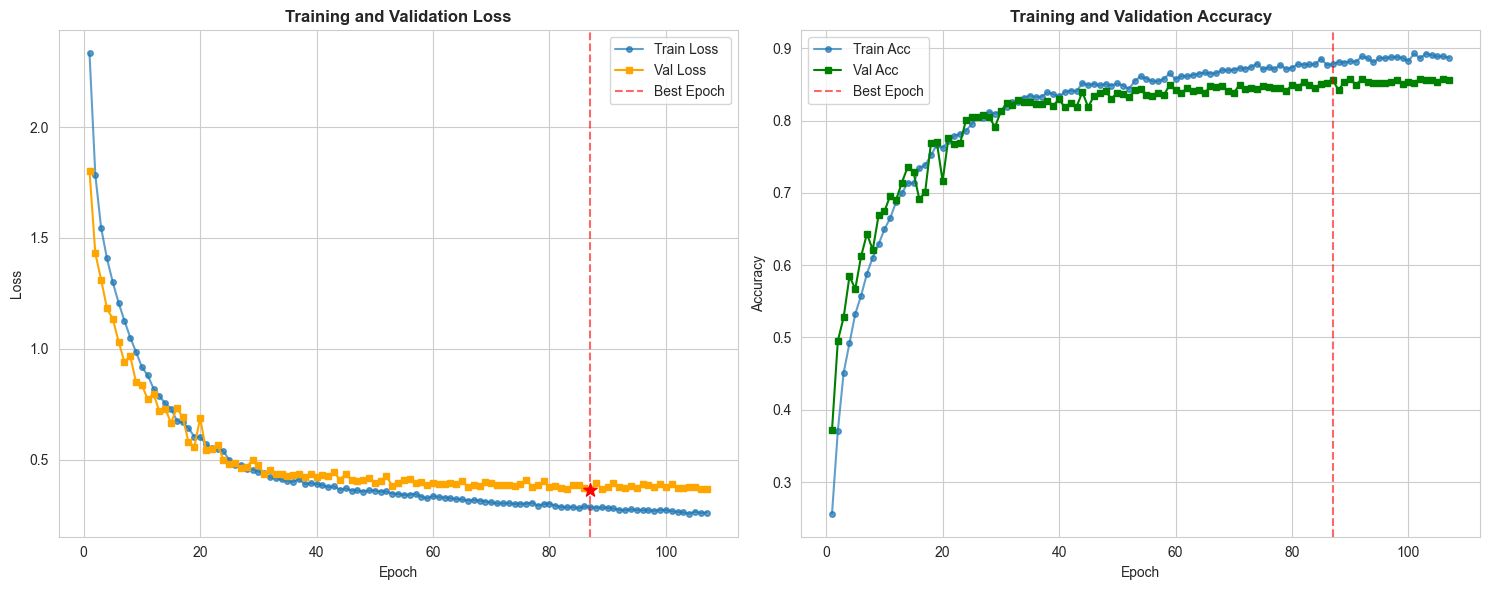

In [ ]:
plot_training_history(history_mag)

## 2.1 Evaluation

In [ ]:
model_mag = Network.load(r"models\har_model_magnitude_v0.nnp")

### 2.1.1 Confisuion matrix

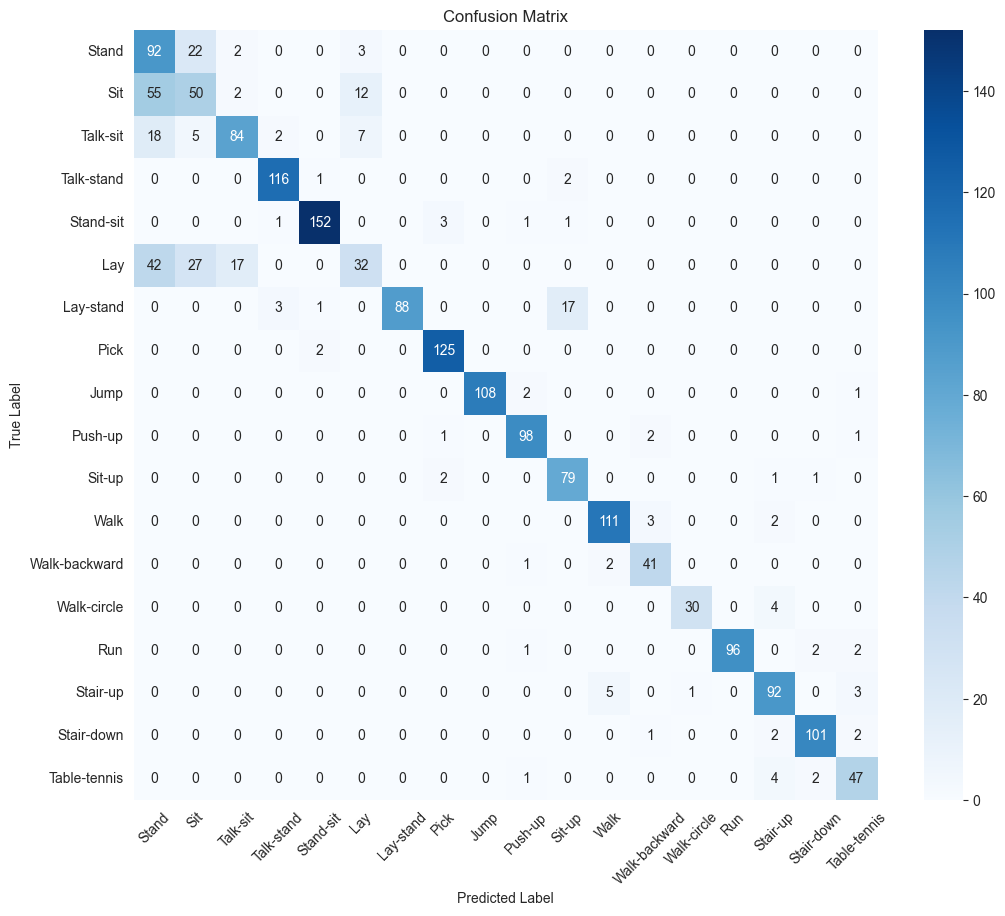

In [ ]:
_preds_mag = model_mag.predict(X_magnitude_test, mask=lengths_magnitude_test)
y_mag_true_idx = np.argmax(Y_magnitude_test, axis=1)
y_mag_pred_idx = np.argmax(_preds_mag, axis=1)
plot_confusion_matrix(
    y_mag_true_idx,
    y_mag_pred_idx,
    model_mag,
    lengths_test=lengths_magnitude_test,
    activity_map=model_mag.activity_labels,
)

### 2.1.2 Metrics per activity

In [ ]:
predictions = model_mag.predict(X_magnitude_test, mask=lengths_magnitude_test)
global_m, class_df = get_detailed_metrics(Y_magnitude_test, predictions, activity_map=model_mag.activity_labels)

In [ ]:
print(class_df)

               precision    recall  f1-score     support
Stand           0.444444  0.773109  0.564417  119.000000
Sit             0.480769  0.420168  0.448430  119.000000
Talk-sit        0.800000  0.724138  0.760181  116.000000
Talk-stand      0.950820  0.974790  0.962656  119.000000
Stand-sit       0.974359  0.962025  0.968153  158.000000
Lay             0.592593  0.271186  0.372093  118.000000
Lay-stand       1.000000  0.807339  0.893401  109.000000
Pick            0.954198  0.984252  0.968992  127.000000
Jump            1.000000  0.972973  0.986301  111.000000
Push-up         0.942308  0.960784  0.951456  102.000000
Sit-up          0.797980  0.951807  0.868132   83.000000
Walk            0.940678  0.956897  0.948718  116.000000
Walk-backward   0.872340  0.931818  0.901099   44.000000
Walk-circle     0.967742  0.882353  0.923077   34.000000
Run             1.000000  0.950495  0.974619  101.000000
Stair-up        0.876190  0.910891  0.893204  101.000000
Stair-down      0.952830  0.952

### 2.1.2.1 F1-score

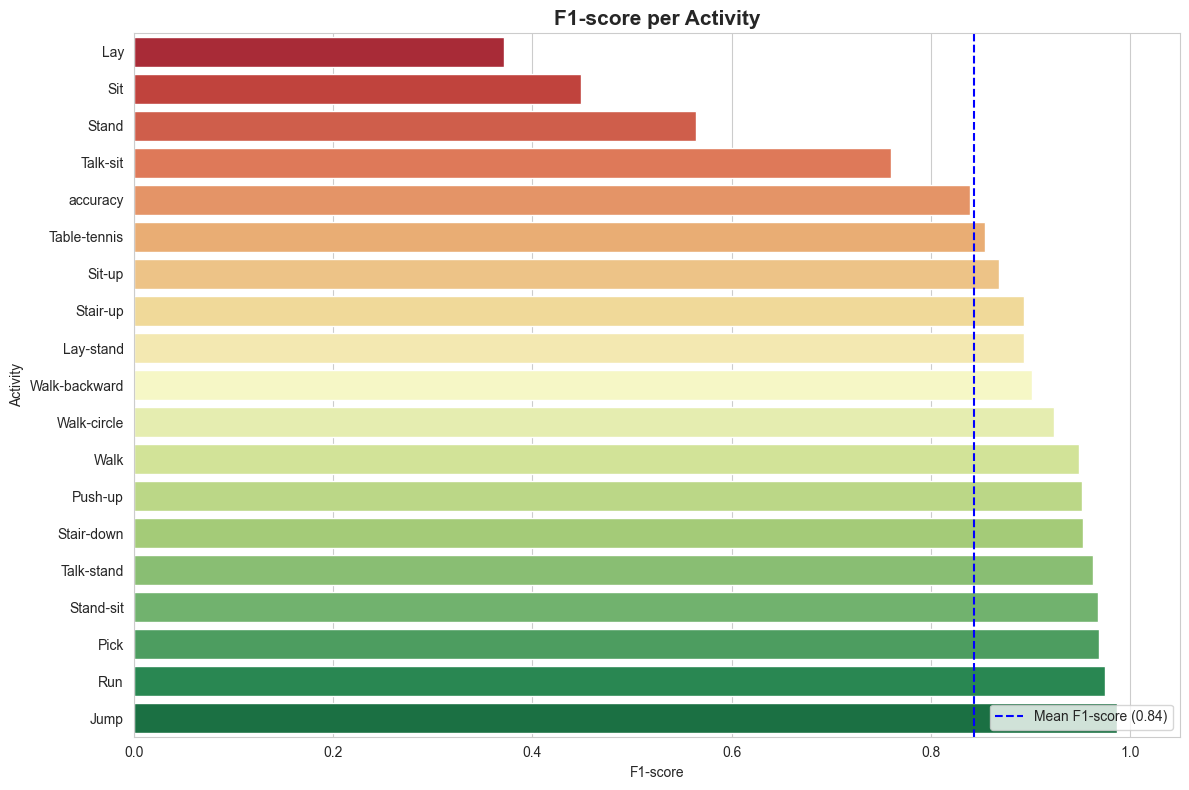

In [ ]:
plot_class_performance(class_df, metric="f1-score")

### 2.1.2.2 Recall

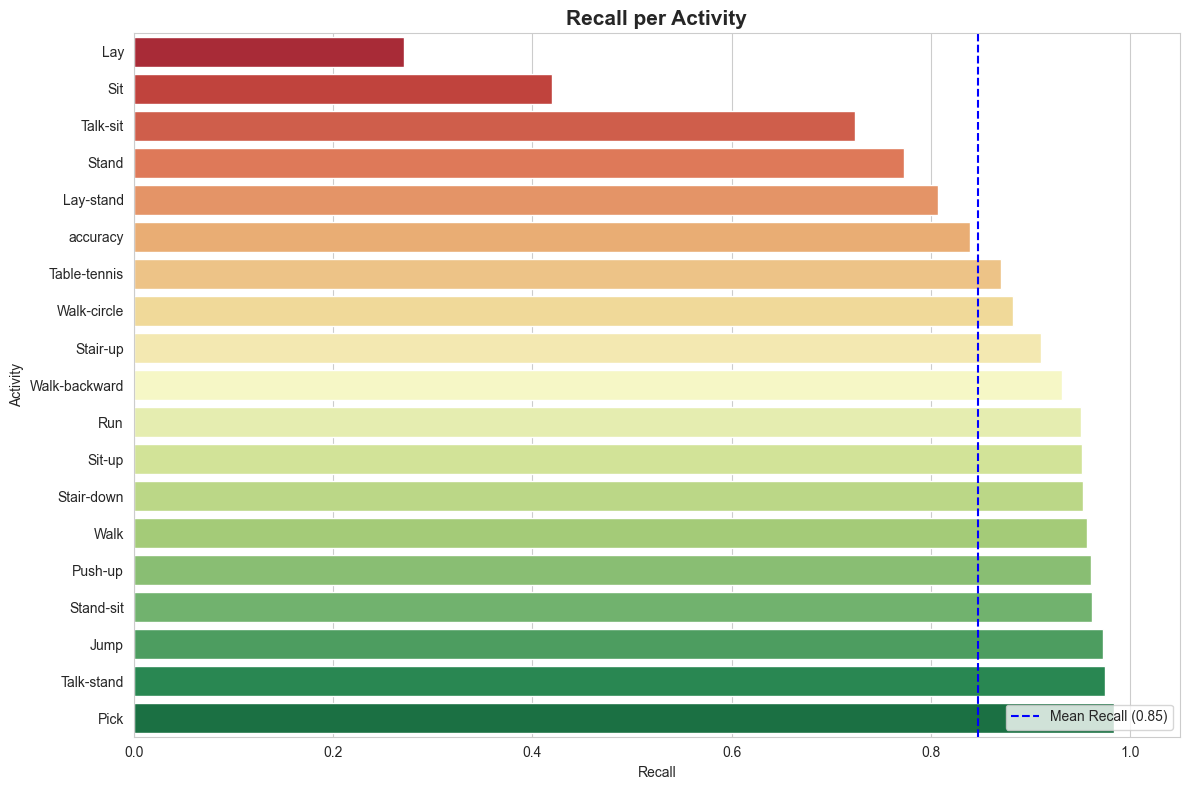

In [ ]:
plot_class_performance(class_df, metric="recall")

### 2.1.2.3 Precision

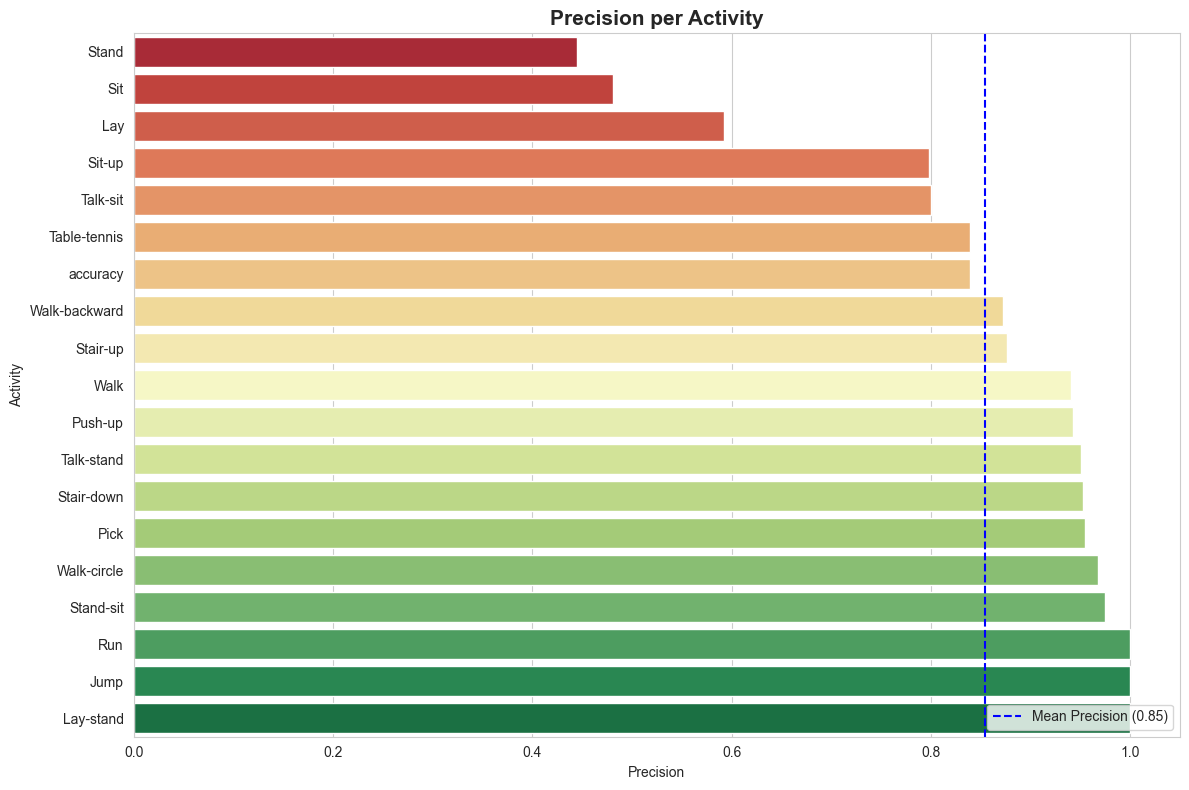

In [ ]:
plot_class_performance(class_df, metric="precision")

### 2.1.2.4 Most confused classes by total misses

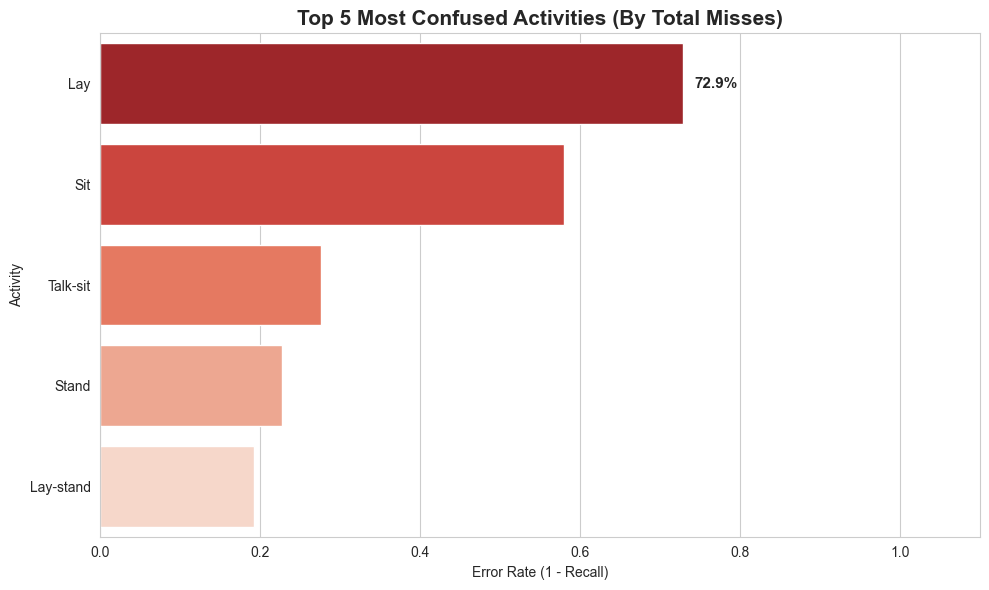

In [ ]:
plot_most_confused_classes(class_df, top_n=5)

### 2.1.2.5 Top mutually confused classes

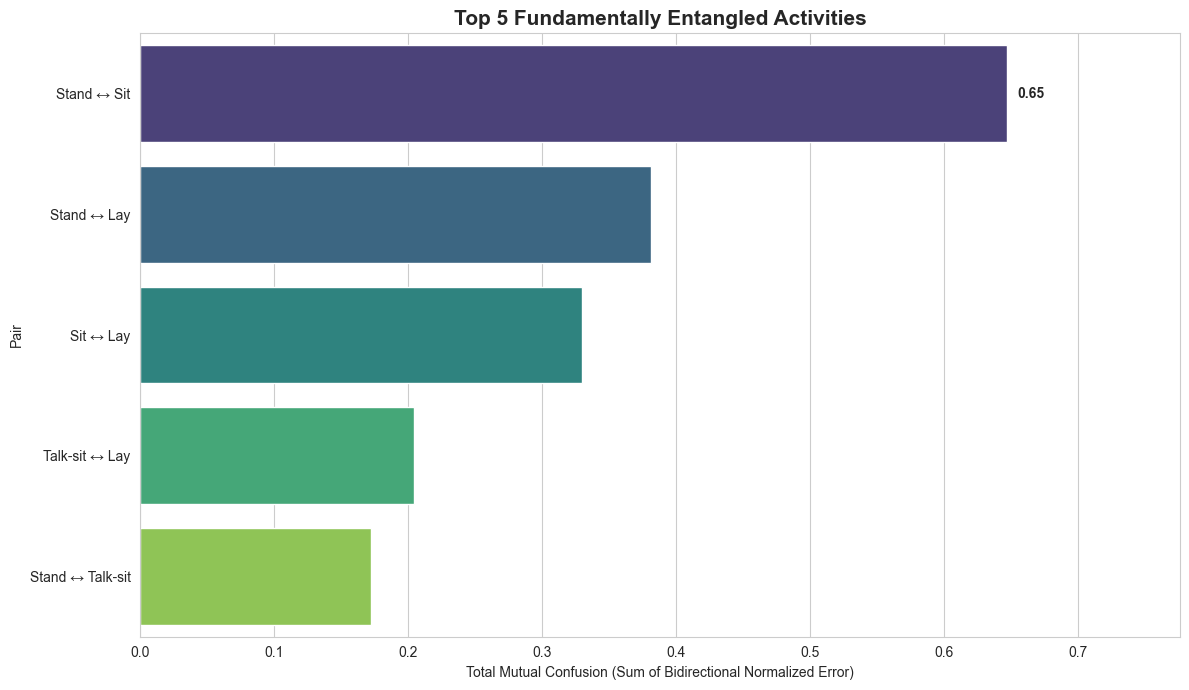

In [ ]:
plot_top_mutual_confusions(Y_magnitude_test, predictions, activity_map, top_n=5)

# 3. Neural network evaluation (hybrid)

In [ ]:
X_HYBRID, Y_HYBRID, LENGHTS_HYBRID, SCALER_HYBRID = prepare_har_dataset(
    dataset_path, mode="hybrid", shuffle=False, random_state=42
)

In [ ]:
_X_tmp, X_hybrid_test, _Y_tmp, Y_hybrid_test_int, _len_tmp, lengths_hybrid_test = train_test_split(
    X_HYBRID, Y_HYBRID, LENGHTS_HYBRID, test_size=0.2, random_state=42, stratify=Y_HYBRID
)
X_hybrid_train, X_hybrid_val, Y_hybrid_train_int, Y_hybrid_val_int, lengths_hybrid_train, lengths_hybrid_val = train_test_split(
    _X_tmp, _Y_tmp, _len_tmp, test_size=0.25, random_state=42, stratify=_Y_tmp
)
del _X_tmp, _Y_tmp, _len_tmp

labels_hybrid = [activity_map[i] for i in range(num_classes)]
Y_hybrid_train = np.eye(num_classes)[Y_hybrid_train_int.astype(int)]
Y_hybrid_val   = np.eye(num_classes)[Y_hybrid_val_int.astype(int)]
Y_hybrid_test  = np.eye(num_classes)[Y_hybrid_test_int.astype(int)]

print(f"Hybrid split  →  Train: {X_hybrid_train.shape[0]}  Val: {X_hybrid_val.shape[0]}  Test: {X_hybrid_test.shape[0]}")
print(f"Class balance (train): {np.bincount(Y_hybrid_train_int)}")

Hybrid split  →  Train: 5511  Val: 1837  Test: 1837
Class balance (train): [358 358 347 356 475 353 325 380 332 308 248 347 130 104 303 305 319 163]


In [ ]:
model_hybrid = prepare_model(labels=labels_hybrid, scaler=SCALER_HYBRID)

history_hybrid, total_time = model_hybrid.fit(
    x_train=X_hybrid_train,
    y_train=Y_hybrid_train,
    x_val=X_hybrid_val,
    y_val=Y_hybrid_val,
    epochs=150,
    batch_size=128,
    verbose=2,
    mask=lengths_hybrid_train,
    val_mask=lengths_hybrid_val,
    lr_decay_epochs=30,
    lr_decay=0.75,
    early_stopping_patience=20,
    early_stopping_min_delta=1e-3,
)

model_hybrid.save(r"models\har_model_hybrid_v0.nnp")

Epoch 1/150, 3.34s/epoch - ETA: 00:08:19
Loss: 2.134889, Acc: 0.3277
Val Loss: 1.386992 - Val Acc: 0.5514
Epoch 3/150, 2.81s/epoch - ETA: 00:07:21
Loss: 1.005373, Acc: 0.6364
Val Loss: 0.775824 - Val Acc: 0.7485
Epoch 5/150, 2.83s/epoch - ETA: 00:07:05
Loss: 0.757791, Acc: 0.7313
Val Loss: 0.622365 - Val Acc: 0.7964
Epoch 7/150, 2.82s/epoch - ETA: 00:06:55
Loss: 0.595634, Acc: 0.7786
Val Loss: 0.563015 - Val Acc: 0.7893
Epoch 9/150, 2.84s/epoch - ETA: 00:06:48
Loss: 0.512369, Acc: 0.8068
Val Loss: 0.485255 - Val Acc: 0.8116
Epoch 11/150, 2.83s/epoch - ETA: 00:06:40
Loss: 0.441951, Acc: 0.8244
Val Loss: 0.451326 - Val Acc: 0.7991
Epoch 13/150, 2.82s/epoch - ETA: 00:06:34
Loss: 0.410175, Acc: 0.8351
Val Loss: 0.391868 - Val Acc: 0.8492
Epoch 15/150, 2.81s/epoch - ETA: 00:06:27
Loss: 0.355503, Acc: 0.8583
Val Loss: 0.368393 - Val Acc: 0.8459
Epoch 17/150, 2.82s/epoch - ETA: 00:06:20
Loss: 0.341590, Acc: 0.8550
Val Loss: 0.359145 - Val Acc: 0.8645
Epoch 19/150, 2.81s/epoch - ETA: 00:06:14


In [ ]:
print(f"Total training time: {total_time:.2f} seconds")
for metric_name, values in history_hybrid.metrics.items():
    print(f"{metric_name}: {values}")

Total training time: 359.33 seconds
train_loss: [2.1348893642425537, 1.3094003200531006, 1.0053731203079224, 0.840607225894928, 0.7577908635139465, 0.6593098640441895, 0.5956340432167053, 0.5448830127716064, 0.5123692750930786, 0.4932876229286194, 0.44195109605789185, 0.41883233189582825, 0.41017475724220276, 0.38010892271995544, 0.35550275444984436, 0.3348816931247711, 0.34159013628959656, 0.32256200909614563, 0.3079536557197571, 0.3082222044467926, 0.29061561822891235, 0.2886444926261902, 0.2677859961986542, 0.278362512588501, 0.2613098919391632, 0.2662273943424225, 0.2765563130378723, 0.2574712336063385, 0.24791911244392395, 0.23931768536567688, 0.22077693045139313, 0.2165829986333847, 0.2147437185049057, 0.20404714345932007, 0.19957461953163147, 0.19937068223953247, 0.1944408118724823, 0.19698825478553772, 0.1917569935321808, 0.1892615407705307, 0.18442367017269135, 0.18554741144180298, 0.17705002427101135, 0.18050605058670044, 0.17874136567115784, 0.16771894693374634, 0.1636859923

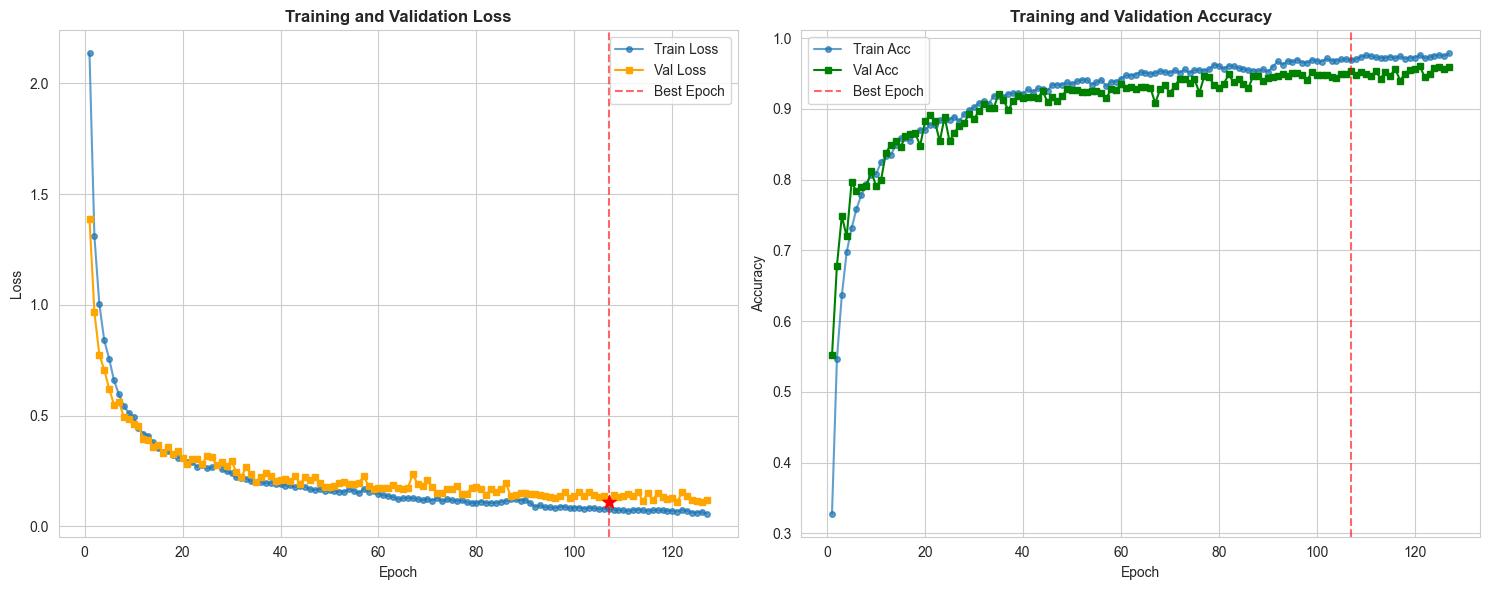

In [ ]:
plot_training_history(history_hybrid)

## 3.1 Evaluation

### 3.1.1 Confisuion matrix

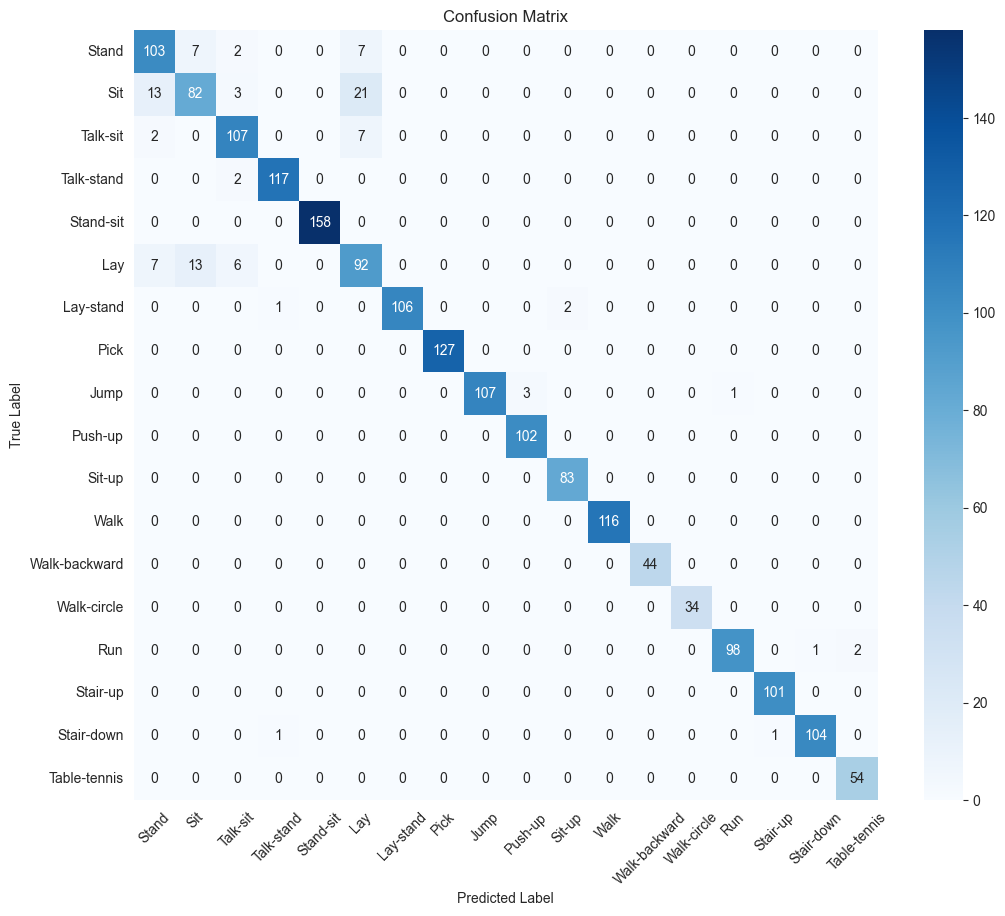

In [ ]:
_preds_hybrid = model_hybrid.predict(X_hybrid_test, mask=lengths_hybrid_test)
y_hybrid_true_idx = np.argmax(Y_hybrid_test, axis=1)
y_hybrid_pred_idx = np.argmax(_preds_hybrid, axis=1)
plot_confusion_matrix(
    y_hybrid_true_idx,
    y_hybrid_pred_idx,
    model_hybrid,
    lengths_test=lengths_hybrid_test,
    activity_map=model_hybrid.activity_labels,
)

### 3.1.2 Metrics per activity

In [ ]:
predictions_hybrid = model_hybrid.predict(X_hybrid_test, mask=lengths_hybrid_test)
global_m_hybrid, class_df_hybrid = get_detailed_metrics(Y_hybrid_test, predictions_hybrid, activity_map)

In [ ]:
print(class_df_hybrid)

               precision    recall  f1-score     support
Stand           0.824000  0.865546  0.844262  119.000000
Sit             0.803922  0.689076  0.742081  119.000000
Talk-sit        0.891667  0.922414  0.906780  116.000000
Talk-stand      0.983193  0.983193  0.983193  119.000000
Stand-sit       1.000000  1.000000  1.000000  158.000000
Lay             0.724409  0.779661  0.751020  118.000000
Lay-stand       1.000000  0.972477  0.986047  109.000000
Pick            1.000000  1.000000  1.000000  127.000000
Jump            1.000000  0.963964  0.981651  111.000000
Push-up         0.971429  1.000000  0.985507  102.000000
Sit-up          0.976471  1.000000  0.988095   83.000000
Walk            1.000000  1.000000  1.000000  116.000000
Walk-backward   1.000000  1.000000  1.000000   44.000000
Walk-circle     1.000000  1.000000  1.000000   34.000000
Run             0.989899  0.970297  0.980000  101.000000
Stair-up        0.990196  1.000000  0.995074  101.000000
Stair-down      0.990476  0.981

### 3.1.2.1 F1-score

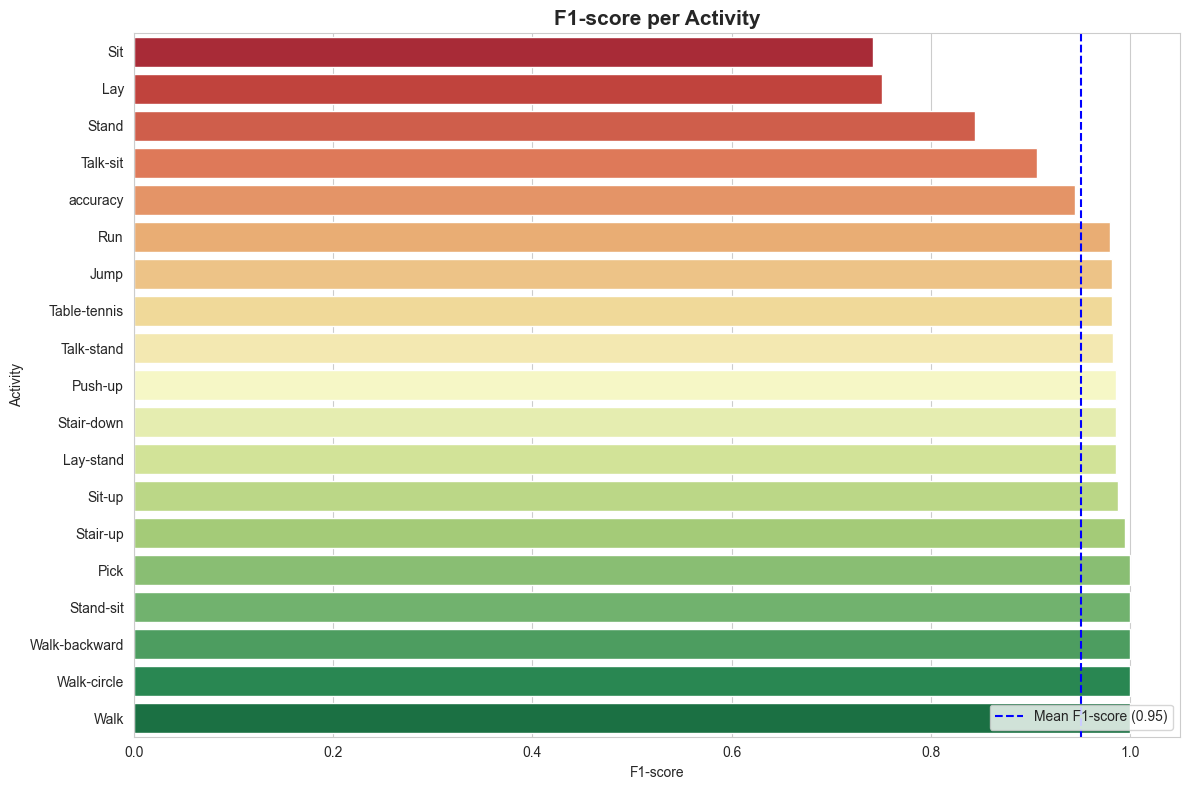

In [ ]:
plot_class_performance(class_df_hybrid, metric="f1-score")

### 3.1.2.2 Recall

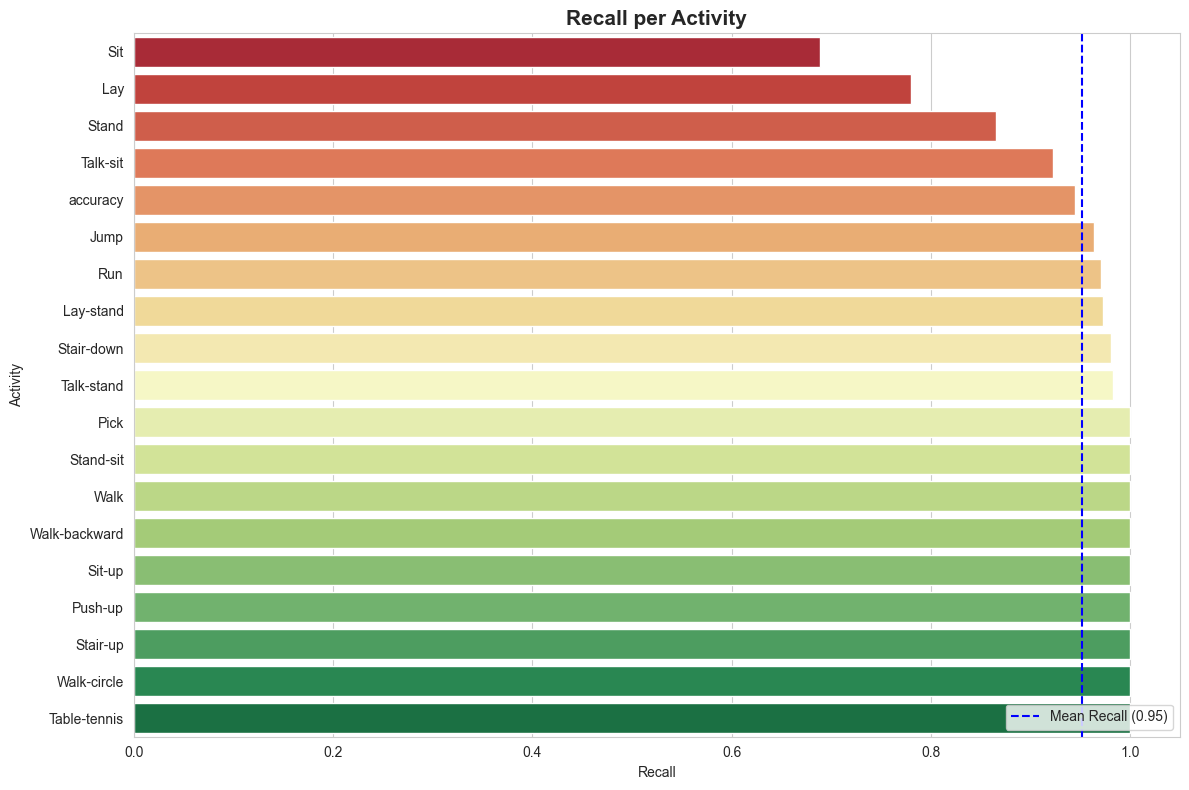

In [ ]:
plot_class_performance(class_df_hybrid, metric="recall")

### 3.1.2.3 Precision

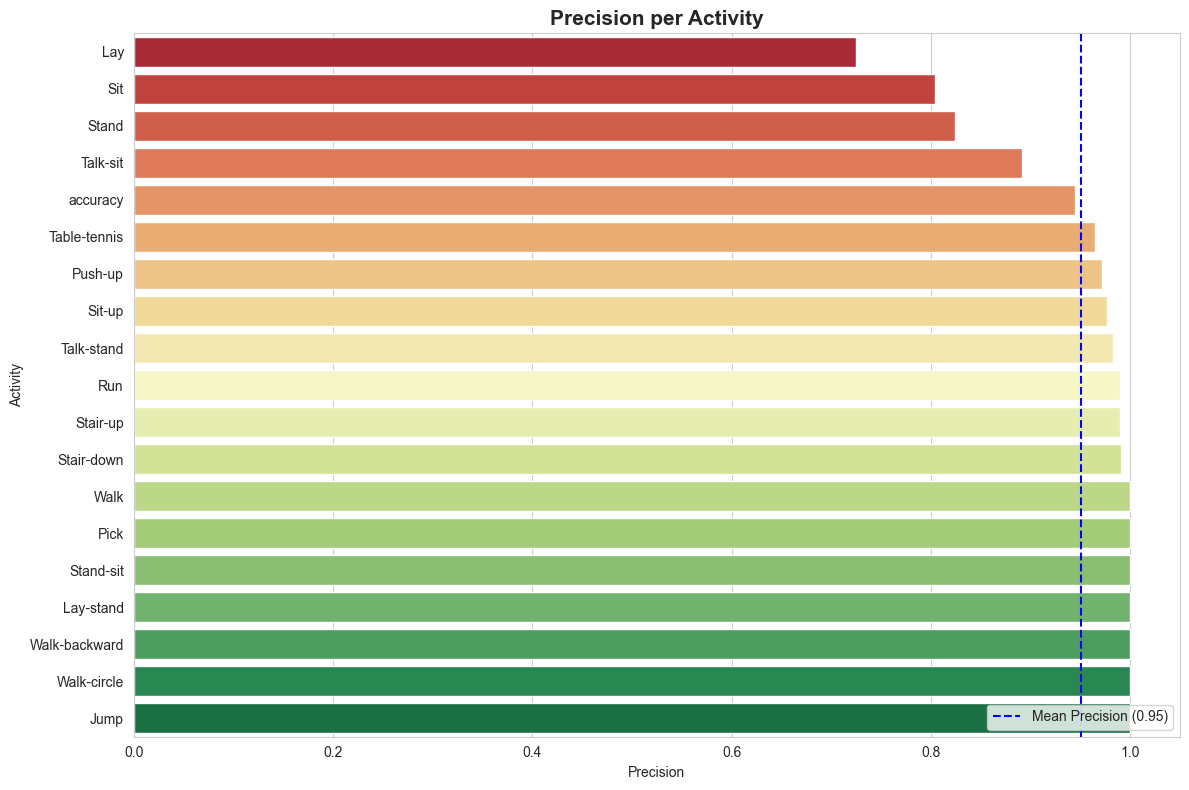

In [ ]:
plot_class_performance(class_df_hybrid, metric="precision")

### 3.1.2.4 Most confused classes by total misses

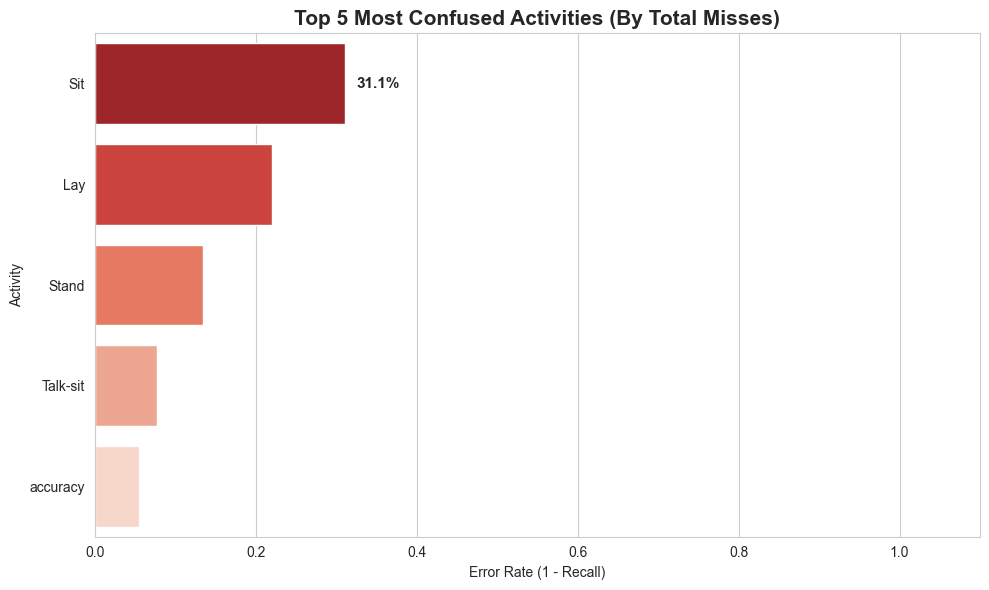

In [ ]:
plot_most_confused_classes(class_df_hybrid, top_n=5)

### 3.1.2.5 Top mutually confused classes

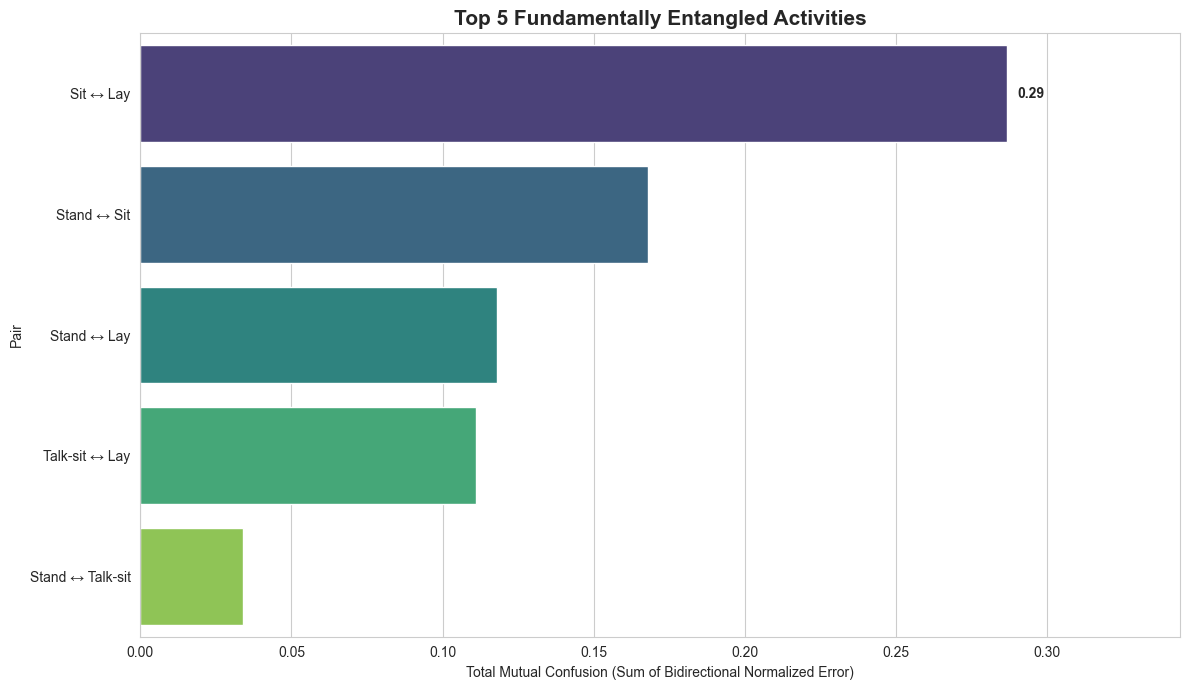

In [ ]:
plot_top_mutual_confusions(Y_hybrid_test, predictions_hybrid, activity_map, top_n=5)